     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 27.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Libraries imported successfully!

Upload your CSV dataset:


Saving nlp dataset.csv to nlp dataset.csv

Dataset loaded successfully!
Dataset shape: (50000, 5)

Columns:
['ID', 'Symptoms/Question', 'Disease Prediction', 'Recommended Medicines', 'Advice']

First 5 records:


,ID,Symptoms/Question,Disease Prediction,Recommended Medicines,Advice
0,1,muscle cramps and weakness,Electrolyte Imbalance,"Electrolyte solution, Potassium supplements","Stay hydrated, maintain balanced diet."
1,2,muscle cramps and weakness,Electrolyte Imbalance,"Electrolyte solution, Potassium supplements","Stay hydrated, maintain balanced diet."
2,3,cold hands and feet,Raynaud's Disease,"Nifedipine, Losartan","Keep warm, reduce stress."
3,4,back pain and stiffness,Herniated Disc,"Ibuprofen, Muscle relaxants","Maintain good posture, apply cold/heat."
4,5,cold hands and feet,Raynaud's Disease,"Nifedipine, Losartan","Keep warm, reduce stress."



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ID                     50000 non-null  int64 
 1   Symptoms/Question      50000 non-null  object
 2   Disease Prediction     50000 non-null  object
 3   Recommended Medicines  50000 non-null  object
 4   Advice                 50000 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.9+ MB

Missing values:
ID                       0
Symptoms/Question        0
Disease Prediction       0
Recommended Medicines    0
Advice                   0
dtype: int64

Dataset after removing ID:


,Symptoms/Question,Disease Prediction,Recommended Medicines,Advice
0,muscle cramps and weakness,Electrolyte Imbalance,"Electrolyte solution, Potassium supplements","Stay hydrated, maintain balanced diet."
1,muscle cramps and weakness,Electrolyte Imbalance,"Electrolyte solution, Potassium supplements","Stay hydrated, maintain balanced diet."
2,cold hands and feet,Raynaud's Disease,"Nifedipine, Losartan","Keep warm, reduce stress."
3,back pain and stiffness,Herniated Disc,"Ibuprofen, Muscle relaxants","Maintain good posture, apply cold/heat."
4,cold hands and feet,Raynaud's Disease,"Nifedipine, Losartan","Keep warm, reduce stress."



Cleaned text:


,Symptoms/Question,Clean Symptoms
0,muscle cramps and weakness,muscle cramps and weakness
1,muscle cramps and weakness,muscle cramps and weakness
2,cold hands and feet,cold hands and feet
3,back pain and stiffness,back pain and stiffness
4,cold hands and feet,cold hands and feet



Number of unique diseases: 20

Disease distribution:
Disease Prediction
Bronchitis               2622
Type 2 Diabetes          2593
Eczema                   2550
Acid Reflux              2537
Dehydration              2533
Electrolyte Imbalance    2513
Gastroenteritis          2508
Lymphadenopathy          2505
Herniated Disc           2501
Pharyngitis              2500
Asthma                   2498
Insomnia                 2491
Rheumatoid Arthritis     2479
Glaucoma                 2475
Meningitis               2468
Raynaud's Disease        2468
Hypertension             2465
Tuberculosis             2448
Heart Disease            2439
Migraine                 2407
Name: count, dtype: int64


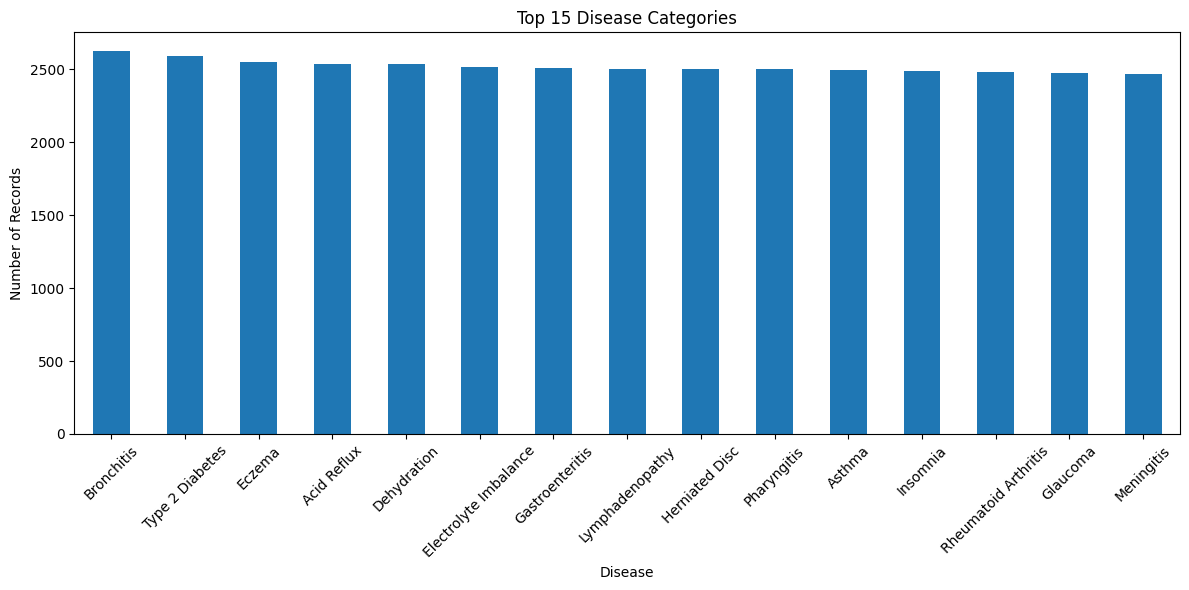


Total input samples: 50000
Number of disease classes: 20

Training samples: 40000
Testing samples: 10000

NLP model created successfully!

Training disease prediction model...
Model training completed!

MODEL PERFORMANCE
Accuracy: 1.0
Accuracy Percentage: 100.0 %

Classification Report:

                       precision    recall  f1-score   support

          Acid Reflux       1.00      1.00      1.00       507
               Asthma       1.00      1.00      1.00       500
           Bronchitis       1.00      1.00      1.00       524
          Dehydration       1.00      1.00      1.00       507
               Eczema       1.00      1.00      1.00       510
Electrolyte Imbalance       1.00      1.00      1.00       503
      Gastroenteritis       1.00      1.00      1.00       501
             Glaucoma       1.00      1.00      1.00       495
        Heart Disease       1.00      1.00      1.00       488
       Herniated Disc       1.00      1.00      1.00       500
         Hyperte

In [ ]:
# ============================================================
# MEDICAL REPORT INFORMATION EXTRACTION
# Natural Language Processing Project
# ============================================================

# ============================================================
# 1. INSTALL REQUIRED LIBRARIES
# ============================================================

!pip install -q pandas numpy scikit-learn spacy matplotlib seaborn
!python -m spacy download en_core_web_sm


# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import re
import spacy
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

from google.colab import files

# Load spaCy model
nlp = spacy.load("en_core_web_sm")

print("Libraries imported successfully!")


# ============================================================
# 3. UPLOAD DATASET
# ============================================================

print("\nUpload your CSV dataset:")
uploaded = files.upload()

# Automatically find uploaded CSV file
csv_file = list(uploaded.keys())[0]

df = pd.read_csv(csv_file)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 4. DISPLAY DATASET
# ============================================================

print("\nFirst 5 records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


# ============================================================
# 5. REMOVE UNNECESSARY ID COLUMN
# ============================================================

if "ID" in df.columns:
    df = df.drop(columns=["ID"])

print("\nDataset after removing ID:")
display(df.head())


# ============================================================
# 6. TEXT CLEANING
# ============================================================

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()


df["Clean Symptoms"] = df["Symptoms/Question"].apply(clean_text)

print("\nCleaned text:")
display(df[["Symptoms/Question", "Clean Symptoms"]].head())


# ============================================================
# 7. CHECK DISEASE INFORMATION
# ============================================================

print("\nNumber of unique diseases:",
      df["Disease Prediction"].nunique())

print("\nDisease distribution:")
print(df["Disease Prediction"].value_counts())


# ============================================================
# 8. VISUALIZE TOP DISEASES
# ============================================================

plt.figure(figsize=(12, 6))

df["Disease Prediction"].value_counts().head(15).plot(
    kind="bar"
)

plt.title("Top 15 Disease Categories")
plt.xlabel("Disease")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# 9. PREPARE INPUT AND TARGET
# ============================================================

X = df["Clean Symptoms"]
y = df["Disease Prediction"]

print("\nTotal input samples:", len(X))
print("Number of disease classes:", y.nunique())


# ============================================================
# 10. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 11. CREATE NLP MODEL
# ============================================================

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            max_features=10000
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000
        )
    )
])

print("\nNLP model created successfully!")


# ============================================================
# 12. TRAIN MODEL
# ============================================================

print("\nTraining disease prediction model...")

model.fit(X_train, y_train)

print("Model training completed!")


# ============================================================
# 13. MODEL EVALUATION
# ============================================================

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\n========================================")
print("MODEL PERFORMANCE")
print("========================================")

print("Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")


# ============================================================
# 14. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


# ============================================================
# 15. SYMPTOM EXTRACTION
# ============================================================

def extract_symptoms(text):

    symptom_keywords = [
        "pain",
        "fever",
        "cough",
        "headache",
        "nausea",
        "vomiting",
        "fatigue",
        "weakness",
        "dizziness",
        "breathing",
        "shortness",
        "diarrhea",
        "constipation",
        "swelling",
        "itching",
        "rash",
        "cold",
        "sore throat",
        "chest pain",
        "stomach pain",
        "body pain",
        "abdominal pain",
        "back pain",
        "joint pain",
        "muscle pain"
    ]

    text_lower = text.lower()

    symptoms = []

    for symptom in symptom_keywords:

        if symptom in text_lower:
            symptoms.append(symptom)

    return list(set(symptoms))


# ============================================================
# 16. MEDICINE RETRIEVAL
# ============================================================

def get_medicines(disease):

    medicines = df[
        df["Disease Prediction"] == disease
    ]["Recommended Medicines"].dropna().unique()

    return medicines


# ============================================================
# 17. ADVICE RETRIEVAL
# ============================================================

def get_advice(disease):

    advice = df[
        df["Disease Prediction"] == disease
    ]["Advice"].dropna().unique()

    return advice


# ============================================================
# 18. COMPLETE MEDICAL INFORMATION EXTRACTOR
# ============================================================

def medical_information_extractor(report):

    # Clean report
    cleaned_report = clean_text(report)

    # Predict disease
    disease = model.predict([cleaned_report])[0]

    # Extract symptoms
    symptoms = extract_symptoms(report)

    # Get medicines
    medicines = get_medicines(disease)

    # Get advice
    advice = get_advice(disease)

    result = {
        "Medical Report": report,
        "Extracted Symptoms": symptoms,
        "Predicted Disease": disease,
        "Recommended Medicines": list(medicines[:5]),
        "Advice": list(advice[:3])
    }

    return result


# ============================================================
# 19. DISPLAY STRUCTURED RESULT
# ============================================================

def display_result(report):

    result = medical_information_extractor(report)

    print("\n")
    print("=" * 60)
    print("        MEDICAL REPORT INFORMATION EXTRACTION")
    print("=" * 60)

    print("\n[INPUT MEDICAL REPORT]")
    print(result["Medical Report"])

    print("\n[EXTRACTED SYMPTOMS]")

    if result["Extracted Symptoms"]:

        for symptom in result["Extracted Symptoms"]:
            print("•", symptom)

    else:

        print("No predefined symptoms detected.")

    print("\n[PREDICTED DIAGNOSIS]")
    print("•", result["Predicted Disease"])

    print("\n[RECOMMENDED MEDICINES]")

    if result["Recommended Medicines"]:

        for medicine in result["Recommended Medicines"]:
            print("•", medicine)

    else:

        print("No medicine information available.")

    print("\n[ADVICE]")

    if result["Advice"]:

        for advice in result["Advice"]:
            print("•", advice)

    else:

        print("No advice available.")

    print("\n" + "=" * 60)


# ============================================================
# 20. TEST WITH SAMPLE MEDICAL REPORT
# ============================================================

sample_report = """
The patient is experiencing fever, headache,
cough and weakness.
"""

display_result(sample_report)


# ============================================================
# 21. TOP 5 DISEASE PREDICTIONS
# ============================================================

def top_disease_predictions(report):

    cleaned_report = clean_text(report)

    probabilities = model.predict_proba(
        [cleaned_report]
    )[0]

    classes = model.classes_

    top_indices = np.argsort(
        probabilities
    )[-5:][::-1]

    print("\n")
    print("=" * 60)
    print("             TOP DISEASE PREDICTIONS")
    print("=" * 60)

    for index in top_indices:

        print(
            classes[index],
            "->",
            round(probabilities[index] * 100, 2),
            "%"
        )


# ============================================================
# 22. TEST TOP PREDICTIONS
# ============================================================

test_report = """
The patient has fever, headache and weakness.
"""

top_disease_predictions(test_report)


# ============================================================
# 23. INTERACTIVE MEDICAL REPORT INPUT
# ============================================================

print("\n")
print("=" * 60)
print("       INTERACTIVE MEDICAL REPORT SYSTEM")
print("=" * 60)

user_report = input(
    "\nEnter your medical report:\n"
)

display_result(user_report)

top_disease_predictions(user_report)


# ============================================================
# 24. SAVE TRAINED MODEL
# ============================================================

joblib.dump(
    model,
    "medical_disease_model.pkl"
)

print("\nTrained model saved as:")
print("medical_disease_model.pkl")


# ============================================================
# 25. DOWNLOAD TRAINED MODEL
# ============================================================

print("\nTo download the trained model, run:")
print("files.download('medical_disease_model.pkl')")



# ============================================================
# 16. DISPLAY RESULT
# ============================================================

def display_result(report):

    result = medical_information_extractor(
        report
    )

    print("\n")
    print("=" * 60)
    print("       MEDICAL INFORMATION EXTRACTION")
    print("=" * 60)

    print("\nSYMPTOMS")

    if result["Symptoms"]:

        for symptom in result["Symptoms"]:
            print("•", symptom)

    else:
        print("No symptoms detected.")

    print("\nDIAGNOSIS")
    print("•", result["Disease"])

    print("\nMEDICINES")

    if result["Medicines"]:

        for medicine in result["Medicines"]:
            print("•", medicine)

    else:
        print("No medicine information available.")

    print("\nADVICE")

    if result["Advice"]:

        for advice in result["Advice"]:
            print("•", advice)

    else:
        print("No advice available.")

    print("=" * 60)


# ============================================================
# 17. ENTER MEDICAL REPORT
# ============================================================

report = input(
    "\nEnter medical report:\n"
)


# ============================================================
# 18. DISPLAY MEDICAL INFORMATION
# ============================================================

display_result(report)


# ============================================================
# 19. SAVE TRAINED MODEL
# ============================================================

joblib.dump(
    model,
    "medical_disease_model.pkl"
)

print(
    "\nModel saved as medical_disease_model.pkl"
)